# HotelIQ – Model Interpretation and Explainability

## Objective

The objective of this notebook is to understand how the trained machine learning model makes hotel booking cancellation predictions.

We will investigate which booking features contribute most to the model's predictions and interpret the results from a business perspective.

### Steps Performed

1. Load the trained Random Forest model.
2. Extract feature importance scores.
3. Identify the most influential features.
4. Visualize feature importance.
5. Summarize the key findings.

### Selected Model

Random Forest Classifier with a classification threshold of 0.40.

In [17]:
# Loading Trained model

import joblib

model_artifact = joblib.load('../models/hotel_cancellation_model.pkl')

#extracting model and threshold
rf_model = model_artifact['model']
best_threshold = model_artifact['threshold']

print("Model loaded successfully!")
print("Selected threshold: ",best_threshold)

Model loaded successfully!
Selected threshold:  0.4


## Extracting and Ranking Feature Importance

The trained Random Forest model provides feature importance scores based on the reduction in impurity across its decision trees.

Higher scores indicate that a feature contributed more to the model's decisions.

We extract the feature names from the fitted preprocessing pipeline and rank them according to their importance scores.

In [18]:
import pandas as pd

In [19]:
# Extract feature names directly from the fitted preprocessor
correct_feature_names = rf_model.named_steps["preprocessor"].get_feature_names_out()

# Extract importance scores
correct_importance_scores = rf_model.named_steps["classifier"].feature_importances_

# Rebuild the DataFrame
feature_importance_df = pd.DataFrame({
    "Feature": correct_feature_names.tolist(),
    "Importance": correct_importance_scores
})

# Sort by importance
feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

# Display the actual feature names
print("First 10 feature names:")
print(feature_importance_df["Feature"].head(10).to_list())

print("\nTop 20 Important Features:")
display(feature_importance_df.head(20))

First 10 feature names:
['num__lead_time', 'num__adr', 'num__arrival_date_day_of_month', 'num__total_of_special_requests', 'num__arrival_date_week_number', 'num__stays_in_week_nights', 'cat__country_PRT', 'num__stays_in_weekend_nights', 'num__required_car_parking_spaces', 'num__arrival_date_year']

Top 20 Important Features:


,Feature,Importance
0,num__lead_time,0.123337
1,num__adr,0.086253
2,num__arrival_date_day_of_month,0.069758
3,num__total_of_special_requests,0.059880
4,num__arrival_date_week_number,0.058208
5,num__stays_in_week_nights,0.049579
6,cat__country_PRT,0.046469
7,num__stays_in_weekend_nights,0.032555
8,num__required_car_parking_spaces,0.026832
9,num__arrival_date_year,0.026798


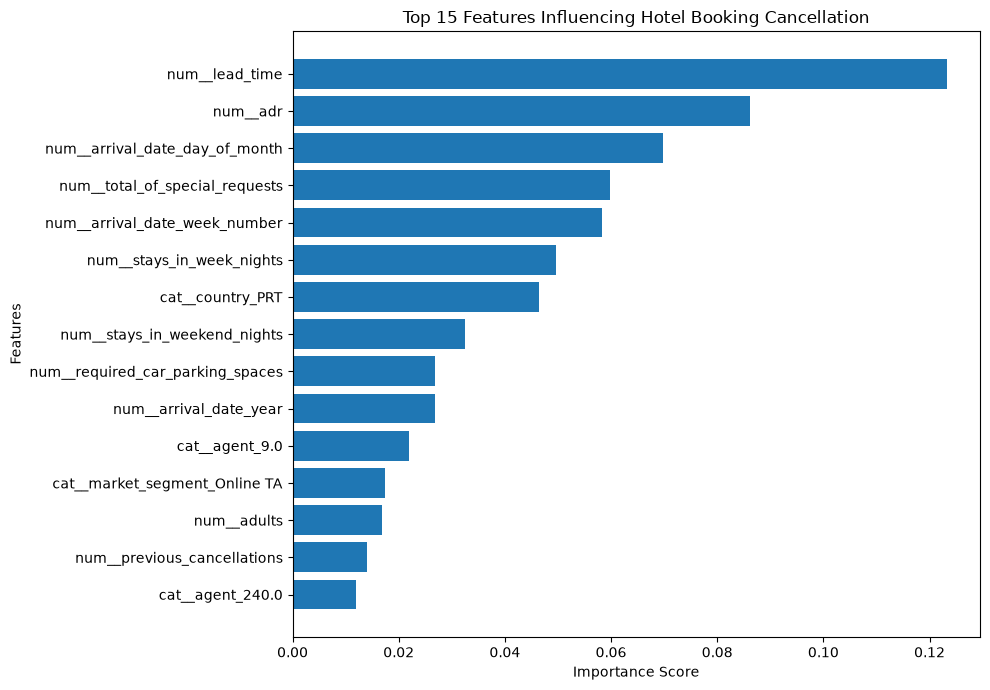

In [20]:
#visualizing Feature Importance
#we visualize the top 15 features identified by the Random Forest model.
#A horizontal bar chart will help us compare the relative importance of different booking characteristics.

import matplotlib.pyplot as plt
top_15_features = feature_importance_df.head(15)

plt.figure(figsize=(10,7))

plt.barh(top_15_features['Feature'], top_15_features['Importance'])

plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.title("Top 15 Features Influencing Hotel Booking Cancellation")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

## Key Findings and Interpretation

The Random Forest model identified the following important features:

- **Lead Time:** The most important feature, with an importance score of approximately 12.33%.
- **ADR:** The second most important feature, contributing approximately 8.63%.
- **Arrival Date:** The day of the month and week number also contributed considerably to model predictions.
- **Special Requests:** The number of special requests was another important feature.
- **Country:** Portugal appeared among the top individual categorical features.

### Business Interpretation

The model relies considerably on booking lead time, ADR, arrival date information, and special requests when predicting cancellations.

These findings can help hotel management understand which booking characteristics are useful for identifying potentially cancelled reservations.

### Important Note

Feature importance represents the contribution of features to the model's predictions. It does not establish a causal relationship with booking cancellations.

The importance scores are based on impurity reduction, so they should be interpreted as model-specific indicators rather than definitive measures of business impact.